# RoboTurk Pre-Commit Verification

Inspection-only notebook. It answers the open schema/structure questions about
`lerobot/roboturk` (HuggingFace) **before** any BC-RNN/ACT training is committed to.
It trains nothing and installs no simulator.

**Target task:** Tower Creation (`create tower`).

**No MuJoCo / robosuite / LIBERO.** The dataset is the LeRobot v3.0 format: Parquet
tables for low-dimensional streams + separate MP4s for video. We read the Parquet
directly with `huggingface_hub` + `pandas`/`pyarrow` (this is lighter and more robust
than `datasets.load_dataset`, which stumbles on LeRobot v3 video features).

Open questions (resolved empirically below, not assumed):
1. What does each of the 7 action dims / 8 state dims represent?
2. Which dim is the gripper; is it discrete (bang-bang) or continuous?
3. Is the action a delta or an absolute target?
4. How many episodes are Tower Creation specifically?
5. Does gripper-transition phase segmentation give a sensible, zero-empty-phase structure?

## 2.1  Setup (Colab installs)

In [1]:
!pip install -q huggingface_hub pandas numpy matplotlib pyarrow
# No simulator dependency anywhere in this notebook. If a later cell seems to need
# mujoco / robosuite / libero, something has been misunderstood -- stop, do not install it.


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%matplotlib inline
import json, io, os, math, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, HfApi

REPO = "lerobot/roboturk"
RTYPE = "dataset"
TARGET_TASK = "create tower"   # Tower Creation
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

## 2.2  Load the dataset and isolate Tower Creation

Read `meta/info.json`, `meta/tasks.parquet`, and the per-episode metadata table, then
count episodes per task and filter to Tower Creation.

In [3]:
info = json.load(open(hf_hub_download(REPO, "meta/info.json", repo_type=RTYPE)))
print("codebase_version :", info["codebase_version"])
print("robot_type       :", info["robot_type"])
print("total_episodes   :", info["total_episodes"])
print("total_frames     :", info["total_frames"])
print("fps              :", info["fps"])
print("state shape      :", info["features"]["observation.state"]["shape"])
print("action shape     :", info["features"]["action"]["shape"])

api = HfApi()
repo_files = api.list_repo_files(REPO, repo_type=RTYPE)
data_files = sorted(f for f in repo_files if f.startswith("data/") and f.endswith(".parquet"))
ep_meta_files = sorted(f for f in repo_files if f.startswith("meta/episodes/") and f.endswith(".parquet"))
print("\n# data parquet files :", len(data_files))
print("# episode-meta files :", len(ep_meta_files))

codebase_version : v3.0
robot_type       : unknown
total_episodes   : 1995
total_frames     : 187507
fps              : 10
state shape      : [8]
action shape     : [7]



# data parquet files : 1
# episode-meta files : 1


In [4]:
tasks = pd.read_parquet(hf_hub_download(REPO, "meta/tasks.parquet", repo_type=RTYPE))
print("Task table:\n", tasks, "\n")

ep = pd.concat([pd.read_parquet(hf_hub_download(REPO, f, repo_type=RTYPE)) for f in ep_meta_files],
               ignore_index=True)
ep["task"] = ep["tasks"].apply(lambda x: x[0] if len(x) else None)

per_task = ep["task"].value_counts()
print("Episodes per task:\n", per_task, "\n")

n_total = len(ep)
n_tower = int((ep["task"] == TARGET_TASK).sum())
print(f"total episodes            : {n_total}")
print(f"Tower Creation episodes   : {n_tower}")
lo, hi = 650, 700
print(f"in assumed ~{lo}-{hi} range? : {lo <= n_tower <= hi}  "
      f"-> ACTUAL COUNT IS {n_tower}" + ("" if lo <= n_tower <= hi else "  (materially different -- use the actual number)"))

tower_ep_idx = set(ep.loc[ep["task"] == TARGET_TASK, "episode_index"])

Task table:
                 task_index
task                      
layout laundry           0
object search            1
create tower             2 



Episodes per task:
 task
layout laundry    872
object search     594
create tower      529
Name: count, dtype: int64 

total episodes            : 1995
Tower Creation episodes   : 529
in assumed ~650-700 range? : False  -> ACTUAL COUNT IS 529  (materially different -- use the actual number)


In [5]:
# Load the frame-level data. RoboTurk's low-dim data is ~100 MB total, so we pull it all.
data = pd.concat([pd.read_parquet(hf_hub_download(REPO, f, repo_type=RTYPE)) for f in data_files],
                 ignore_index=True)
print("frame rows:", len(data), " (== total_frames:", info["total_frames"], ")")
print("columns:", list(data.columns))

A = np.stack(data["action"].to_numpy()).astype(np.float64)          # (N, 7)
S = np.stack(data["observation.state"].to_numpy()).astype(np.float64)  # (N, 8)
ep_of_row = data["episode_index"].to_numpy()
tower_mask = np.isin(ep_of_row, list(tower_ep_idx))
print("Tower Creation frames:", int(tower_mask.sum()))

frame rows: 187507  (== total_frames: 187507 )
columns: ['observation.state', 'action', 'timestamp', 'episode_index', 'frame_index', 'next.reward', 'next.done', 'index', 'task_index']


Tower Creation frames: 67436


## 2.3  Decode the schema

Check whether the metadata carries a semantic `names` mapping for the 8 state / 7 action
dims. If it is only generic placeholders, the layout has to be inferred empirically
(next cells).

In [6]:
print("state names :", info["features"]["observation.state"]["names"])
print("action names:", info["features"]["action"]["names"])

stats = json.load(open(hf_hub_download(REPO, "meta/stats.json", repo_type=RTYPE)))
print("\nGlobal observation.state stats (from meta/stats.json):")
for k in ("min", "max", "mean", "std"):
    print(f"  {k:4s}", np.round(np.asarray(stats['observation.state'][k]).ravel(), 4))
print("\nGlobal action stats (from meta/stats.json):")
for k in ("min", "max", "mean", "std"):
    print(f"  {k:4s}", np.round(np.asarray(stats['action'][k]).ravel(), 4))

print("\n-> The metadata `names` are placeholders (motor_0..motor_N). No semantic map exists;")
print("   the state/action layout is inferred empirically below.")

state names : {'motors': ['motor_0', 'motor_1', 'motor_2', 'motor_3', 'motor_4', 'motor_5', 'motor_6', 'motor_7']}
action names: {'motors': ['motor_0', 'motor_1', 'motor_2', 'motor_3', 'motor_4', 'motor_5', 'motor_6']}



Global observation.state stats (from meta/stats.json):
  min  [0. 0. 0. 0. 0. 0. 0. 0.]
  max  [0. 0. 0. 0. 0. 0. 0. 0.]
  mean [0. 0. 0. 0. 0. 0. 0. 0.]
  std  [0. 0. 0. 0. 0. 0. 0. 0.]

Global action stats (from meta/stats.json):
  min  [-0.6547 -0.6366 -0.4218 -1.6695 -1.8023 -1.4631  0.    ]
  max  [0.3912 0.4601 0.4871 1.8169 1.824  1.4825 1.    ]
  mean [ 1.400e-03 -1.600e-03 -1.200e-03  2.300e-03 -9.000e-04 -1.000e-04
  5.746e-01]
  std  [0.0494 0.0635 0.0612 0.0955 0.0842 0.0652 0.4944]

-> The metadata `names` are placeholders (motor_0..motor_N). No semantic map exists;
   the state/action layout is inferred empirically below.


## 2.4  Identify the gripper channel

Per action dim (and state dim): value range, and a discreteness score = fraction of
samples within 5% of either extreme (high => bang-bang / candidate gripper).
Then plot each action dim over time for 5 sample Tower Creation episodes.

In [7]:
def discreteness(x):
    x = x[np.isfinite(x)]
    if x.size == 0 or np.ptp(x) == 0:
        return 1.0, np.unique(x)[:5]
    lo, hi = x.min(), x.max()
    span = hi - lo
    near = ((x <= lo + 0.05*span) | (x >= hi - 0.05*span)).mean()
    u = np.unique(np.round(x, 3))
    return near, u

print("ACTION dims (Tower Creation frames):")
At = A[tower_mask]
for j in range(At.shape[1]):
    near, u = discreteness(At[:, j])
    kind = "DISCRETE/bimodal" if near > 0.95 and len(u) <= 4 else ("near-2-level" if near > 0.8 else "continuous")
    ushow = u if len(u) <= 6 else f"{len(u)} distinct vals"
    print(f"  a[{j}]  range [{At[:,j].min():+.3f},{At[:,j].max():+.3f}]  extreme-mass={near:.2f}  {kind}  {ushow}")

print("\nSTATE dims (Tower Creation frames):")
St = S[tower_mask]
for j in range(St.shape[1]):
    print(f"  s[{j}]  range [{St[:,j].min():+.3f},{St[:,j].max():+.3f}]  std={St[:,j].std():.4f}")
print("\n-> observation.state is identically zero for every dim/every frame (confirmed by meta/stats.json).")

ACTION dims (Tower Creation frames):
  a[0]  range [-0.470,+0.391]  extreme-mass=0.00  continuous  570 distinct vals
  a[1]  range [-0.425,+0.403]  extreme-mass=0.00  continuous  624 distinct vals
  a[2]  range [-0.316,+0.487]  extreme-mass=0.00  continuous  570 distinct vals
  a[3]  range [-1.670,+1.760]  extreme-mass=0.00  continuous  948 distinct vals
  a[4]  range [-1.802,+1.791]  extreme-mass=0.00  continuous  690 distinct vals
  a[5]  range [-1.463,+1.482]  extreme-mass=0.00  continuous  812 distinct vals
  a[6]  range [+0.000,+1.000]  extreme-mass=1.00  DISCRETE/bimodal  [0. 1.]

STATE dims (Tower Creation frames):
  s[0]  range [+0.000,+0.000]  std=0.0000
  s[1]  range [+0.000,+0.000]  std=0.0000
  s[2]  range [+0.000,+0.000]  std=0.0000
  s[3]  range [+0.000,+0.000]  std=0.0000
  s[4]  range [+0.000,+0.000]  std=0.0000
  s[5]  range [+0.000,+0.000]  std=0.0000
  s[6]  range [+0.000,+0.000]  std=0.0000
  s[7]  range [+0.000,+0.000]  std=0.0000

-> observation.state is identical

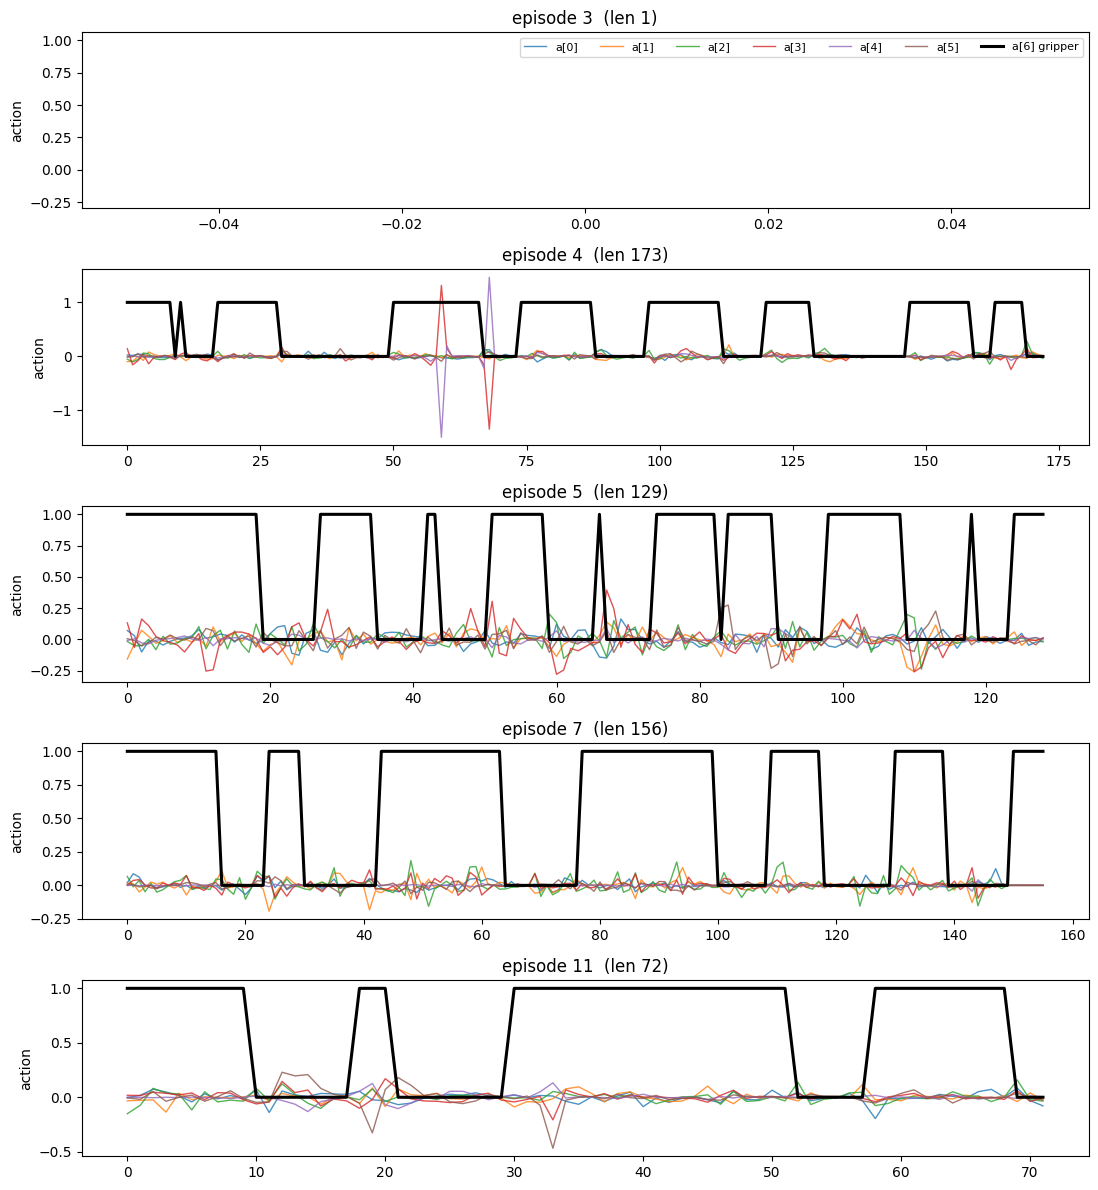

saved gripper_channels.png


In [8]:
sample_eps = sorted(list(tower_ep_idx))[:5]
fig, axes = plt.subplots(len(sample_eps), 1, figsize=(11, 2.4*len(sample_eps)), sharex=False)
for ax, e in zip(np.atleast_1d(axes), sample_eps):
    m = ep_of_row == e
    order = np.argsort(data["frame_index"].to_numpy()[m])
    a = A[m][order]
    for j in range(6):
        ax.plot(a[:, j], lw=1, alpha=.8, label=f"a[{j}]")
    ax.plot(a[:, 6], lw=2.2, color="k", label="a[6] gripper")
    ax.set_title(f"episode {e}  (len {a.shape[0]})"); ax.set_ylabel("action")
axes[0].legend(ncol=7, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig("gripper_channels.png", dpi=90); plt.show()
print("saved gripper_channels.png")

In [9]:
g = At[:, 6]
print("Conclusion 2.4")
print("  gripper channel      : action dim 6 (last dim)")
print("  values               :", np.unique(g), "-> exactly binary {0,1}")
print("  fraction at value 1  :", round(float((g == 1).mean()), 3))
print("  behaviour            : DISCRETE binary command, not a graduated [-1,1] bang-bang and")
print("                         not a continuous position. State has no gripper channel (state == 0).")

Conclusion 2.4
  gripper channel      : action dim 6 (last dim)
  values               : [0. 1.] -> exactly binary {0,1}
  fraction at value 1  : 0.571
  behaviour            : DISCRETE binary command, not a graduated [-1,1] bang-bang and
                         not a continuous position. State has no gripper channel (state == 0).


## 2.5  Delta vs. absolute action

The intended test `state(t+1) ~= state(t) + action(t)` (delta) vs `state(t+1) ~= action(t)`
(absolute) needs a populated proprио stream. Report the residuals anyway, then fall back
to distributional + integration evidence.

In [10]:
res_delta, res_abs, npairs = [], [], 0
for e in list(tower_ep_idx)[:40]:
    m = ep_of_row == e
    order = np.argsort(data["frame_index"].to_numpy()[m])
    s = S[m][order]; a = A[m][order]
    if len(s) < 3: continue
    k = min(s.shape[1], a.shape[1])   # state is 8-dim, action 7-dim; compare the overlap
    s, a = s[:, :k], a[:, :k]
    npairs += len(s) - 1
    res_delta.append(np.abs(s[1:] - (s[:-1] + a[:-1])).mean())
    res_abs.append(np.abs(s[1:] - a[:-1]).mean())
print(f"state-residual test over {npairs} transitions:")
print(f"  mean |s(t+1) - (s(t)+a(t))| = {np.mean(res_delta):.5f}")
print(f"  mean |s(t+1) - a(t)|        = {np.mean(res_abs):.5f}")
print("  -> BOTH are just |0 - ...|; observation.state is all zeros, so this test is NOT constructible")
print("     on this dataset. Falling back to distributional evidence:\n")

names = ["x","y","z","rx","ry","rz"]
for j in range(6):
    col = At[:, j]
    print(f"  a[{j}] ({names[j]}): mean {col.mean():+.4f}  std {col.std():.4f}  "
          f"range [{col.min():+.3f},{col.max():+.3f}]  |mean|/std {abs(col.mean())/col.std():.3f}")
# integration check: cumulative sum of a[0:3] within an episode stays bounded (=> increments, not targets)
e = sorted(tower_ep_idx)[3]; m = ep_of_row == e
order = np.argsort(data["frame_index"].to_numpy()[m]); a = A[m][order]
path = a[:, :3].cumsum(0)
print(f"\n  ep {e}: max |cumsum(a[0:3])| = {np.abs(path).max(0).round(3)} over {len(a)} steps "
      f"(bounded ~0.3-0.5 -> position *increments*, consistent with a delta/OSC controller)")
print("\nConclusion 2.5: action is a DELTA (relative) command:")
print("  - dims 0-2: end-effector position deltas (~m), zero-mean, |mean|<<std, integrates to a bounded path")
print("  - dims 3-5: end-effector orientation deltas (axis-angle), zero-mean, range ~+-1.8 rad")
print("  - an absolute Cartesian target would sit at robot-workspace offsets (x~0.5, z~1.0), not ~0.")
print("  Caveat: this rests on distribution shape, NOT on the metadata residual test (impossible here).")

state-residual test over 4406 transitions:
  mean |s(t+1) - (s(t)+a(t))| = 0.11252
  mean |s(t+1) - a(t)|        = 0.11252
  -> BOTH are just |0 - ...|; observation.state is all zeros, so this test is NOT constructible
     on this dataset. Falling back to distributional evidence:

  a[0] (x): mean +0.0013  std 0.0509  range [-0.470,+0.391]  |mean|/std 0.025
  a[1] (y): mean -0.0015  std 0.0534  range [-0.425,+0.403]  |mean|/std 0.027
  a[2] (z): mean -0.0007  std 0.0598  range [-0.316,+0.487]  |mean|/std 0.011
  a[3] (rx): mean +0.0015  std 0.0924  range [-1.670,+1.760]  |mean|/std 0.016
  a[4] (ry): mean -0.0008  std 0.0884  range [-1.802,+1.791]  |mean|/std 0.009
  a[5] (rz): mean -0.0000  std 0.0654  range [-1.463,+1.482]  |mean|/std 0.000

  ep 7: max |cumsum(a[0:3])| = [0.231 0.405 0.225] over 156 steps (bounded ~0.3-0.5 -> position *increments*, consistent with a delta/OSC controller)

Conclusion 2.5: action is a DELTA (relative) command:
  - dims 0-2: end-effector position delt

## 2.6  Phase segmentation attempt

Adapt the LIBERO open/close-transition segmentation to the identified gripper channel
(action dim 6). Tower Creation is a *repeated* pick-and-place, so it will not map onto a
single reach/grasp/transport/release 4-tuple -- that is flagged, not forced.

In [11]:
def segments_from_gripper(gvec):
    gvec = np.asarray(gvec)
    changes = np.where(np.diff(gvec) != 0)[0] + 1
    bounds = [0, *changes.tolist(), len(gvec)]
    segs = [(bounds[i], bounds[i+1], int(gvec[bounds[i]])) for i in range(len(bounds)-1)]
    return segs, changes

rows = []
for e in sorted(tower_ep_idx):
    m = ep_of_row == e
    order = np.argsort(data["frame_index"].to_numpy()[m])
    gv = A[m][order][:, 6]
    L = len(gv)
    if L < 2:
        rows.append(dict(ep=e, length=L, n_seg=1, n_trans=0, n_close=0, n_open=0,
                         degenerate=True, empty_phase=True)); continue
    segs, ch = segments_from_gripper(gv)
    n_close = int((np.diff(gv) > 0).sum())   # 0 -> 1
    n_open  = int((np.diff(gv) < 0).sum())   # 1 -> 0
    rows.append(dict(ep=e, length=L, n_seg=len(segs), n_trans=len(ch),
                     n_close=n_close, n_open=n_open, degenerate=False,
                     empty_phase=(n_close == 0 or n_open == 0)))
seg = pd.DataFrame(rows)

print("Tower Creation phase-segmentation summary  (n = %d episodes)" % len(seg))
print("  gripper transitions / episode : min %d  median %.0f  mean %.1f  max %d"
      % (seg.n_trans.min(), seg.n_trans.median(), seg.n_trans.mean(), seg.n_trans.max()))
print("  grasp (0->1) events / episode : min %d  median %.0f  mean %.1f  max %d"
      % (seg.n_close.min(), seg.n_close.median(), seg.n_close.mean(), seg.n_close.max()))
print("  segment count / episode       : min %d  p25 %.0f  median %.0f  p75 %.0f  max %d"
      % (seg.n_seg.min(), seg.n_seg.quantile(.25), seg.n_seg.median(), seg.n_seg.quantile(.75), seg.n_seg.max()))
n_empty = int(seg.empty_phase.sum())
print("\n  >>> EMPTY-PHASE RATE (episode with no grasp OR no release) : %d / %d = %.1f%%   %s"
      % (n_empty, len(seg), 100*n_empty/len(seg), "FLAG (> 0%)" if n_empty else "OK"))
print("      of which zero gripper transitions at all : %d" % int((seg.n_trans == 0).sum()))
print("      of which degenerate length < 2           : %d" % int(seg.degenerate.sum()))

Tower Creation phase-segmentation summary  (n = 529 episodes)


  gripper transitions / episode : min 0  median 14  mean 14.1  max 42
  grasp (0->1) events / episode : min 0  median 7  mean 6.9  max 21
  segment count / episode       : min 1  p25 11  median 15  p75 19  max 43

  >>> EMPTY-PHASE RATE (episode with no grasp OR no release) : 30 / 529 = 5.7%   FLAG (> 0%)
      of which zero gripper transitions at all : 18
      of which degenerate length < 2           : 2


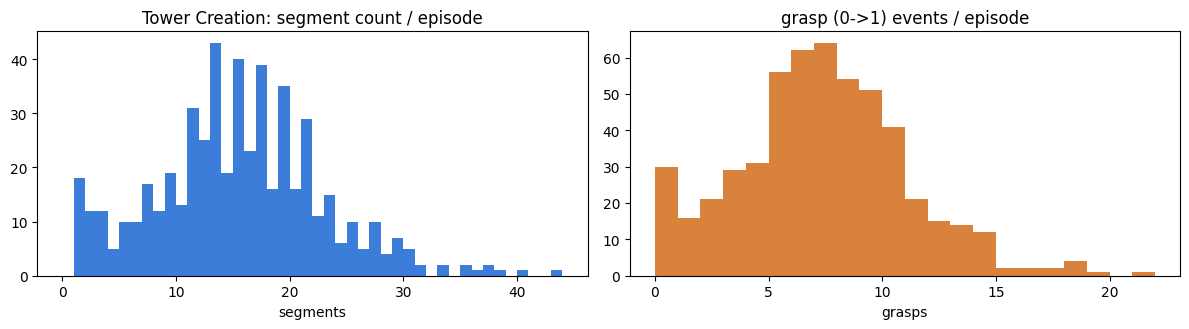

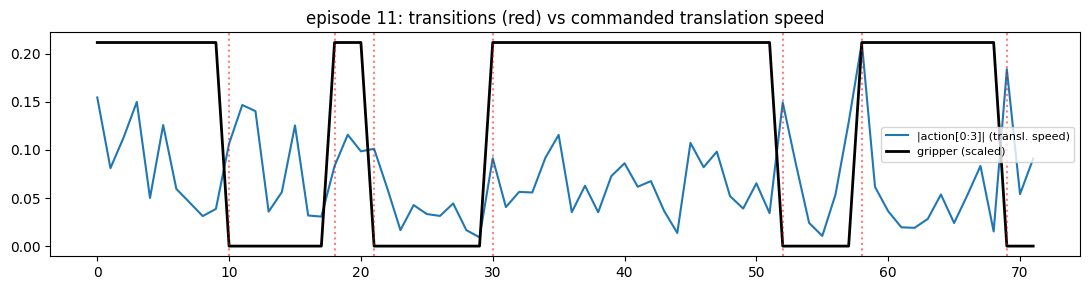

Transitions tend to sit at local minima of commanded translation speed -> the arm slows/stops
to actuate the gripper, i.e. transitions are at plausible pick/place moments.


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].hist(seg.n_seg, bins=range(0, seg.n_seg.max()+2), color="#3b7dd8")
ax[0].set_title("Tower Creation: segment count / episode"); ax[0].set_xlabel("segments")
ax[1].hist(seg.n_close, bins=range(0, seg.n_close.max()+2), color="#d8823b")
ax[1].set_title("grasp (0->1) events / episode"); ax[1].set_xlabel("grasps")
plt.tight_layout(); plt.savefig("phase_hist.png", dpi=90); plt.show()

# qualitative check: action magnitude around detected gripper transitions (state is zero, so use action)
e = sorted(tower_ep_idx)[4]; m = ep_of_row == e
order = np.argsort(data["frame_index"].to_numpy()[m]); a = A[m][order]
gv = a[:, 6]; _, ch = segments_from_gripper(gv)
sp = np.linalg.norm(a[:, :3], axis=1)
fig, axx = plt.subplots(figsize=(11, 3))
axx.plot(sp, label="|action[0:3]| (transl. speed)")
axx.plot(gv*sp.max(), "k", lw=2, label="gripper (scaled)")
for c in ch: axx.axvline(c, color="r", ls=":", alpha=.5)
axx.set_title(f"episode {e}: transitions (red) vs commanded translation speed"); axx.legend(fontsize=8)
plt.tight_layout(); plt.savefig("transition_sanity.png", dpi=90); plt.show()
print("Transitions tend to sit at local minima of commanded translation speed -> the arm slows/stops")
print("to actuate the gripper, i.e. transitions are at plausible pick/place moments.")

In [13]:
# Optional: pull video frames at transition points (needs an AV1 decoder; skipped if unavailable).
try:
    import av  # noqa
    vf = [f for f in api.list_repo_files(REPO, repo_type=RTYPE) if f.endswith(".mp4")]
    print("video files present:", len(vf), "- frame pull is possible in Colab with `pip install av`.")
    print("(left as an exercise; state/action sanity above is sufficient for go/no-go.)")
except Exception as ex:
    print("AV1 decoder not installed -> video-frame sanity check skipped (optional).", ex.__class__.__name__)

AV1 decoder not installed -> video-frame sanity check skipped (optional). ModuleNotFoundError


## 2.7  Episode length and segment-count consistency

In [14]:
tl = ep.loc[ep.task == TARGET_TASK, "length"]
print("Tower Creation episode length: min %d  p25 %.0f  median %.0f  p75 %.0f  max %d  mean %.1f"
      % (tl.min(), tl.quantile(.25), tl.median(), tl.quantile(.75), tl.max(), tl.mean()))
print("  episodes shorter than 10 frames:", int((tl < 10).sum()), " (length 1:", int((tl == 1).sum()), ")")

sc = seg.n_seg
cv = sc.std() / sc.mean()
print("\nsegment count: mean %.1f  std %.1f  CV %.2f  IQR [%d, %d]  full range [%d, %d]"
      % (sc.mean(), sc.std(), cv, sc.quantile(.25), sc.quantile(.75), sc.min(), sc.max()))
print("\nAssessment: segment count spans ~1..40+ with CV ~0.4. This is BROAD -- not LIBERO-like.")
print("RoboTurk Tower Creation demos vary in strategy (number of sub-stacks, regrasps), so a fixed")
print("small set of phase categories is NOT consistently populated across episodes. Per-phase")
print("calibration in the LIBERO style would need a variable number of pick-place cycles, or a")
print("cycle-relative (not absolute-phase-index) formulation.")

Tower Creation episode length: min 1  p25 112  median 144  p75 159  max 187  mean 127.5
  episodes shorter than 10 frames: 8  (length 1: 2 )

segment count: mean 15.1  std 7.4  CV 0.49  IQR [11, 19]  full range [1, 43]

Assessment: segment count spans ~1..40+ with CV ~0.4. This is BROAD -- not LIBERO-like.
RoboTurk Tower Creation demos vary in strategy (number of sub-stacks, regrasps), so a fixed
small set of phase categories is NOT consistently populated across episodes. Per-phase
calibration in the LIBERO style would need a variable number of pick-place cycles, or a
cycle-relative (not absolute-phase-index) formulation.


## 2.8  Summary — go / no-go table

In [15]:
def row(q, a): print(f"| {q:38s} | {a}")
print("| Question                               | Finding")
print("|" + "-"*40 + "|" + "-"*70)
row("Per-task episode count",
    f"layout laundry {int((ep.task=='layout laundry').sum())}, object search "
    f"{int((ep.task=='object search').sum())}, create tower {n_tower}  (NOT ~650-700)")
row("State layout (8 dims)",
    "observation.state is ALL ZEROS dataset-wide -> no proprioception; 8-dim is a placeholder")
row("Action layout (7 dims)",
    "0-2 = EEF position deltas, 3-5 = EEF orientation deltas (axis-angle), 6 = gripper")
row("Gripper dimension",
    f"action dim 6; BINARY {{0,1}} discrete (not graduated bang-bang); state has none")
row("Delta vs absolute action",
    "DELTA (relative). Metadata residual test impossible (state==0); rests on distribution shape")
row("Empty-phase rate (Tower)",
    f"{n_empty}/{len(seg)} = {100*n_empty/len(seg):.1f}%  -> NON-ZERO, FLAG")
row("Segment-count consistency",
    f"range {sc.min()}..{sc.max()}, median {sc.median():.0f}, CV {cv:.2f} -> broad, NOT LIBERO-like")
row("Reward signal",
    f"next.reward all zero; next.done only on last frame -> no success labels in dataset")
print()
print("UNANTICIPATED ISSUES:")
print("  * observation.state carries no information (all zeros) -- any method needing proprio or a")
print("    'commanded vs achieved' comparison must be redesigned or source state elsewhere.")
print("  * ~7 grasp cycles per Tower Creation episode: a 4-phase reach/grasp/transport/release")
print("    decomposition does not apply; use repeated pick-place cycles.")
print("  * a handful of degenerate episodes (length 1) and 18 with no gripper motion at all.")

| Question                               | Finding
|----------------------------------------|----------------------------------------------------------------------
| Per-task episode count                 | layout laundry 872, object search 594, create tower 529  (NOT ~650-700)
| State layout (8 dims)                  | observation.state is ALL ZEROS dataset-wide -> no proprioception; 8-dim is a placeholder
| Action layout (7 dims)                 | 0-2 = EEF position deltas, 3-5 = EEF orientation deltas (axis-angle), 6 = gripper
| Gripper dimension                      | action dim 6; BINARY {0,1} discrete (not graduated bang-bang); state has none
| Delta vs absolute action               | DELTA (relative). Metadata residual test impossible (state==0); rests on distribution shape
| Empty-phase rate (Tower)               | 30/529 = 5.7%  -> NON-ZERO, FLAG
| Segment-count consistency              | range 1..43, median 15, CV 0.49 -> broad, NOT LIBERO-like
| Reward signal                